In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import joblib
import shap

# PROYECTO FINAL

In [ ]:
#cargar
DATA = '/content/drive/MyDrive/ProyectoFinal/Large_Cars_Dataset.csv'

df = pd.read_csv(DATA)

print(f"Dataset: {df.shape[0]} filas y {df.shape[1]} columnas")
print("\nColumnas:")
print(f"{list(df.columns)}\n")
display(df.head())

In [ ]:
#PREPROCESMANIENTO

#descarts
cols_drop = ['Brand', 'Model', 'VehicleClass', 'Region', 'DriveTrain', 'MSRP', 'DealerCost', 'Length', 'Wheelbase']
df = df.drop(columns=cols_drop)

#EPA
df['MPG_Combined'] = (df['MPG_City'] * 0.55) + (df['MPG_Highway'] * 0.45)
df = df.drop(columns=['MPG_City', 'MPG_Highway'])

df = df.dropna()

#EDA
plt.figure(figsize=(8, 5))
sns.histplot(df['MPG_Combined'], kde=True, bins=20, color='steelblue')
plt.title('Distribucion Consumo Promedio de Combustible (MPG)')
plt.xlabel('MPG Combinado')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Matriz de Correlacion")
plt.show()

=== MODELO BASELINE ===
RMSE (Baseline): 2.05 MPG
MAE (Baseline): 1.66 MPG

=== MODELO DEEP LEARNING ===


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
RMSE (DL): 1.78 MPG
MAE (DL): 1.35 MPG


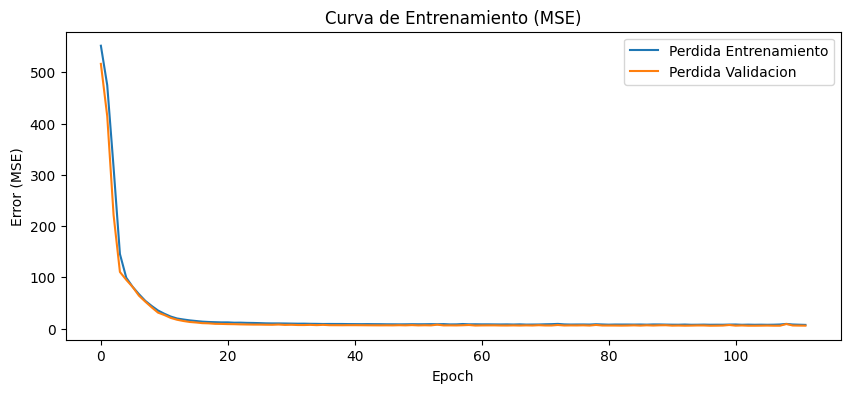

In [11]:
#ENTRENAMIENTO
X = df.drop('MPG_Combined', axis=1)
y = df['MPG_Combined']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

print("=== MODELO BASELINE ===")
baseline = LinearRegression()
baseline.fit(X_train_scale, y_train)
y_pred_base = baseline.predict(X_test_scale)

rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
mae_base = mean_absolute_error(y_test, y_pred_base)

print(f"RMSE (Baseline): {rmse_base:.2f} MPG")
print(f"MAE (Baseline): {mae_base:.2f} MPG\n")

#mero modelo
print("=== MODELO DEEP LEARNING ===")
model = models.Sequential([
    layers.Dense(64, activation='relu', input_shape=(X_train_scale.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history = model.fit(
    X_train_scale, y_train,
    validation_split=0.2,
    epochs=150,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

y_pred_deep = model.predict(X_test_scale).flatten()
rmse_deep = np.sqrt(mean_squared_error(y_test, y_pred_deep))
mae_deep = mean_absolute_error(y_test, y_pred_deep)

print(f"RMSE (DL): {rmse_deep:.2f} MPG")
print(f"MAE (DL): {mae_deep:.2f} MPG")

#grafica
plt.figure(figsize=(10, 4))
plt.plot(history.history['loss'], label='Perdida Entrenamiento')
plt.plot(history.history['val_loss'], label='Perdida Validacion')
plt.title('Curva de Entrenamiento (MSE)')
plt.xlabel('Epoch')
plt.ylabel('Error (MSE)')
plt.legend()
plt.show()


In [ ]:
#modelo
model.save('modelo_cars.h5')
joblib.dump(scaler, 'scaler_cars.pkl')
joblib.dump(list(X.columns), 'features_cars.pkl')

from google.colab import files
files.download('modelo_cars.h5')
files.download('scaler_cars.pkl')
files.download('features_cars.pkl')

print("...Archivos listos...")

In [ ]:
#curva de valor
"""
Caso del Honda Civic 2015 EX-L
cilindros: 4
tamaño motor: 1.5 L
HP: 176
peso: 3053 lbs

Caso 1
11/8/26
$3.34/galon (Q25.4/galon), total: $32.53 (Q247.23)
305 millas
Caso 2
11/14/26
$3.30/galón (Q25.1/galón), total: $31.71 (Q241)
290 millas
Caso 3
11/15/26
$3.30/galón (Q25.1/galón), total: $16.5 (Q125.4)
164 millas
"""
import matplotlib.pyplot as plt
import numpy as np

millas_prom= 250  #prom carga
galones_reales = 9.0 #aprox
precio_galon = 25.2#promedio precios
costo_real = galones_reales * precio_galon

#errores simulados
rmse_simulado = np.linspace(3.0, 0.5, 100)

galones_esperados = millas_prom / (millas_prom / galones_reales + rmse_simulado)
costo_estimado = galones_esperados * precio_galon
#dif
desv_costo = costo_estimado - costo_real

#grafica
plt.figure(figsize=(10, 6))
plt.plot(rmse_simulado, abs(desv_costo), color='red', linewidth=2, label='Margen Error Presupuestario')
plt.axvline(x=2.05, color='blue', linestyle='--', label='Baseline (RMSE 2.05)')
plt.axvline(x=1.73, color='purple', linestyle='--', label='MLP (RMSE 1.73)')
plt.title('Curva de Valor')
plt.xlabel('RMSE Modelo (MPG)')
plt.ylabel('Desviacion Costo Estimado (Q)')
plt.legend()
plt.grid(True, alpha=0.5)
plt.gca().invert_xaxis()
plt.text(2.6, max(abs(desv_costo))*0.8, 'Peor precision', fontsize=10, color='black')
plt.text(1.0, max(abs(desv_costo))*0.2, 'Mejor precision', fontsize=10, color='black')

plt.tight_layout()
plt.show()

# LABORATORIO 10

=== SHAP ===
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


  0%|          | 0/50 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step

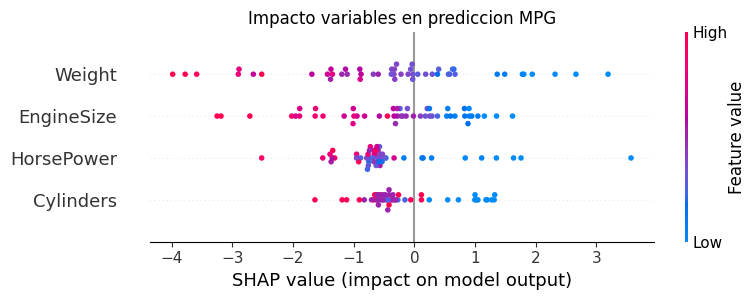

In [17]:
#shap
print("=== SHAP ===")

X_background = X_train_scale[:100]

explainer = shap.KernelExplainer(lambda x: model.predict(x).flatten(), X_background)
shap_values = explainer.shap_values(X_test_scale[:50])

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_scale[:50], feature_names=X.columns, show=False)
plt.title("Impacto variables en prediccion MPG")
plt.tight_layout()
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


  0%|          | 0/5 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

=== Explicacion Local - Instancia 1 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Prediccion modelo: 22.55 MPG


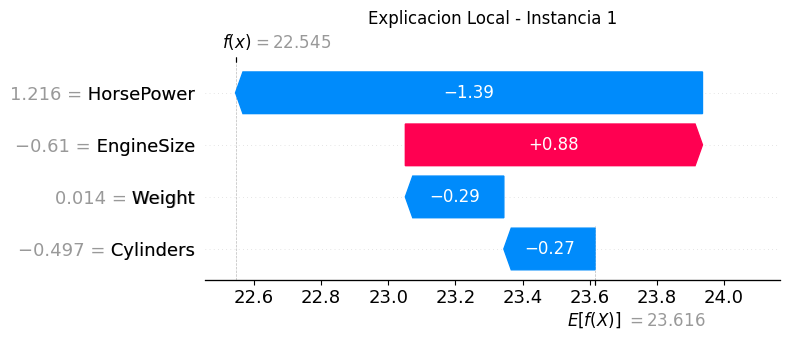


=== Explicacion Local - Instancia 2 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Prediccion modelo: 22.72 MPG


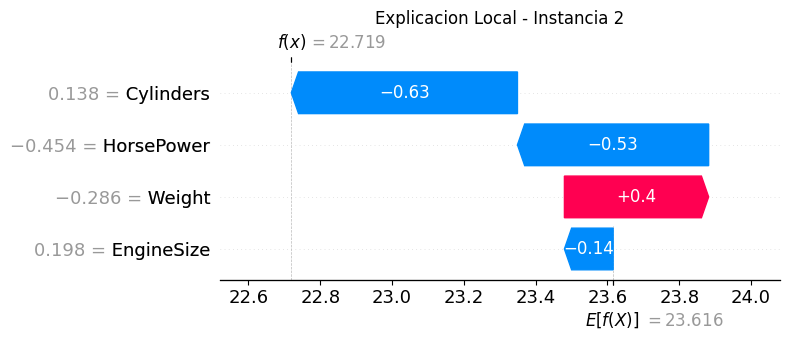


=== Explicacion Local - Instancia 3 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Prediccion modelo: 21.46 MPG


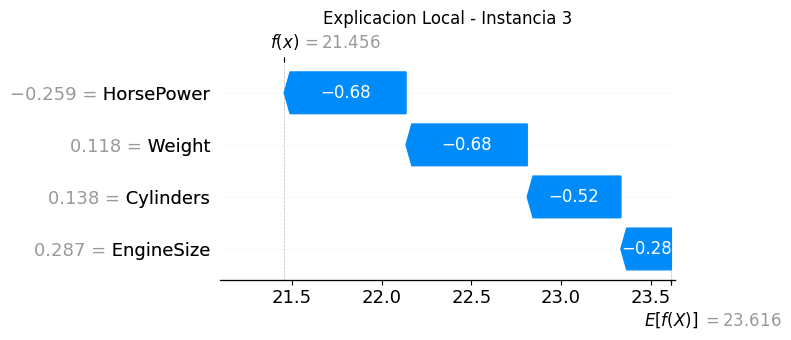


=== Explicacion Local - Instancia 4 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Prediccion modelo: 22.89 MPG


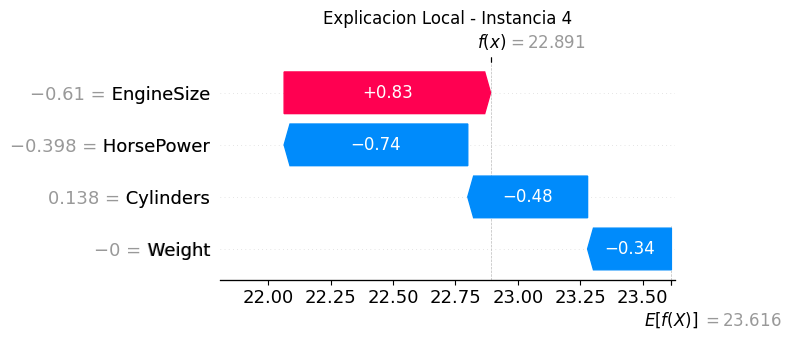


=== Explicacion Local - Instancia 5 ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
Prediccion modelo: 22.67 MPG


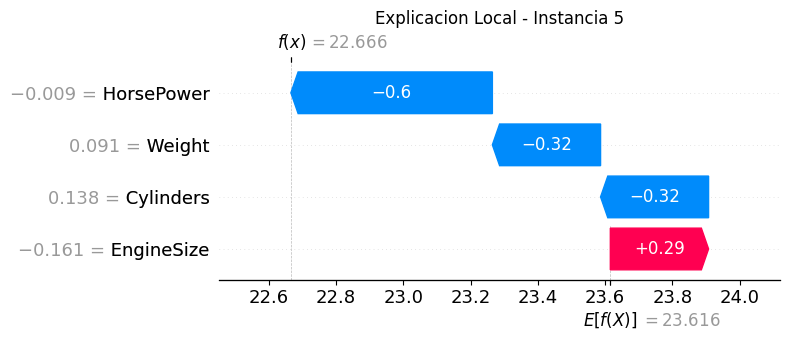

In [19]:
#semilla
np.random.seed(42)

#ecplainer
X_background = X_train_scale[:100]
explainer = shap.KernelExplainer(lambda x: model.predict(x).flatten(), X_background)

#instancias
X_sample = X_test_scale[:5]
shap_values_sample = explainer.shap_values(X_sample)

#graficas
for i in range(5):
    print(f"\n=== Explicacion Local - Instancia {i+1} ===")
    print(f"Prediccion modelo: {model.predict(X_sample[i:i+1]).flatten()[0]:.2f} MPG")

    plt.figure(figsize=(10, 4))
    shap.waterfall_plot(
        shap.Explanation(
            values=shap_values_sample[i],
            base_values=explainer.expected_value,
            data=X_sample[i],
            feature_names=X.columns
        ),
        show=False
    )
    plt.title(f"Explicacion Local - Instancia {i+1}")
    plt.tight_layout()
    plt.show()